# Titanic Survival — Exploratory Data Analysis

The goal of this notebook is to understand the data and define the preprocessing for a neural-network classifier that predicts passenger survival (`Survived`). All analysis uses the training set only.

| Term | Meaning |
| --- | --- |
| Full dataset | Kaggle `train.csv`, all rows |
| Training set | 80% of the full dataset, used for all analysis |
| Test set | 20% of the full dataset, held out for final evaluation |

**Sections**

0. Introduction and setup
1. Data overview
2. Target
3. Missing values
4. Categorical variables (`Sex`, `Embarked`)
5. Discrete numeric variables (`Pclass`, `SibSp`, `Parch`)
6. Continuous variables (`Age`, `Fare`)
7. Text columns (`Name`, `Ticket`, `Cabin`)
8. Correlation between the remaining features
9. Summary
10. Applying the preprocessing

## 0. Setup

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter

# The notebook lives in the project root; make sure the root is on sys.path so `src` can be imported.
PROJECT_ROOT = Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_download import ensure_train_csv
from src.data_split import split_dataset

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "train.csv"
SEED = 42
TEST_SIZE = 0.2
TARGET = "Survived"

COLOR_MAIN = "#2a78d6"
COLOR_REFERENCE = "#52514e"
CORR_CMAP = sns.diverging_palette(30, 250, s=80, l=55, center="light", as_cmap=True)

In [3]:
# Downloads train.csv from Kaggle if it is not in data/ yet (see src/data_download.py for credentials).
ensure_train_csv(DATA_PATH)

full_df = pd.read_csv(DATA_PATH)
train_df, test_df = split_dataset(full_df, test_size=TEST_SIZE, seed=SEED)

print(f"Full dataset rows: {len(full_df)}")
print(f"Training set rows: {len(train_df)}")
print(f"Test set rows:     {len(test_df)}")

Full dataset rows: 891
Training set rows: 712
Test set rows:     179


### Helpers

In [4]:
def show_table(table: pd.DataFrame, table_id: str, caption: str) -> None:
    """Print a caption line with the table ID, then display the table."""
    print(f"Table {table_id}: {caption}")
    display(table)


def plot_survival_rate(
    ax: plt.Axes, groups: pd.Series, target: pd.Series, overall_rate: float, order: list | None = None
) -> None:
    """Bar chart of the survival rate per group, with n above each bar and a dashed line at the overall rate."""
    stats = target.groupby(groups).agg(rate="mean", n="size")
    if order is not None:
        stats = stats.reindex(order)
    positions = np.arange(len(stats))
    bars = ax.bar(positions, stats["rate"].to_numpy(), color=COLOR_MAIN, width=0.7)
    ax.bar_label(bars, labels=[f"{rate:.0%}\nn={n}" for rate, n in zip(stats["rate"], stats["n"])], padding=3, fontsize=8)
    ax.set_xticks(positions, [str(level) for level in stats.index])
    ax.axhline(overall_rate, color=COLOR_REFERENCE, linestyle="--", linewidth=1.2, label=f"Overall survival rate ({overall_rate:.1%})")
    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc="upper right", fontsize=8)

## 1. Data overview

**Question:** What does each column contain?

**What is shown:** Table 1.1 lists every column of `train_df` with its meaning from the Kaggle data dictionary, its stored type, its number of unique values and its share of missing values. The line below it gives the number of duplicated rows when `PassengerId` is ignored.

In [5]:
# Column meanings from the Kaggle Titanic data dictionary.
COLUMN_MEANINGS = {
    "PassengerId": "Passenger identifier",
    "Survived": "Survival (0 = No, 1 = Yes)",
    "Pclass": "Ticket class (1 = 1st, 2 = 2nd, 3 = 3rd)",
    "Name": "Passenger name",
    "Sex": "Sex",
    "Age": "Age in years",
    "SibSp": "Number of siblings / spouses aboard",
    "Parch": "Number of parents / children aboard",
    "Ticket": "Ticket number",
    "Fare": "Passenger fare",
    "Cabin": "Cabin number",
    "Embarked": "Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton)",
}

overview = pd.DataFrame(
    {
        "meaning": [COLUMN_MEANINGS[column] for column in train_df.columns],
        "dtype": train_df.dtypes.astype(str).to_numpy(),
        "unique values": train_df.nunique().to_numpy(),
        "missing %": (100 * train_df.isna().mean()).round(1).to_numpy(),
    },
    index=pd.Index(train_df.columns, name="column"),
)
show_table(overview, "1.1", f"Columns of the training set ({len(train_df)} rows)")

duplicated_rows = train_df.drop(columns="PassengerId").duplicated().sum()
print(f"Duplicated rows (PassengerId ignored): {duplicated_rows}")

Table 1.1: Columns of the training set (712 rows)


,meaning,dtype,unique values,missing %
column,,,,
PassengerId,Passenger identifier,int64,712,0.0
Survived,"Survival (0 = No, 1 = Yes)",int64,2,0.0
Pclass,"Ticket class (1 = 1st, 2 = 2nd, 3 = 3rd)",int64,3,0.0
Name,Passenger name,str,712,0.0
Sex,Sex,str,2,0.0
Age,Age in years,float64,85,19.2
SibSp,Number of siblings / spouses aboard,int64,7,0.0
Parch,Number of parents / children aboard,int64,7,0.0
Ticket,Ticket number,str,571,0.0


Duplicated rows (PassengerId ignored): 0


**Decision:**

- Drop `PassengerId` (identifier).

## 2. Target

**Question:** How is the target distributed?

**What is shown:** Fig 2.1 shows the number of passengers in each class of `Survived` (0 = did not survive, 1 = survived); the label on each bar gives the count and its share of `train_df`.

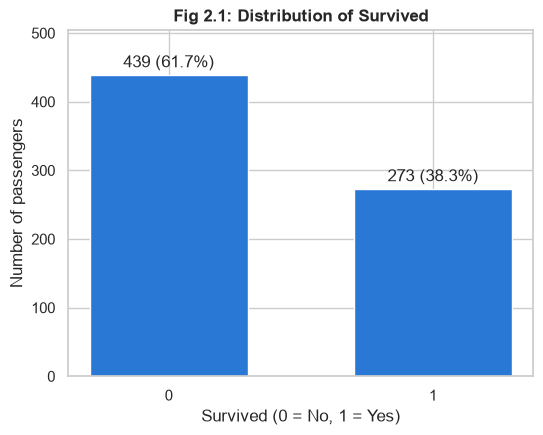

In [6]:
counts = train_df[TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(counts.index.astype(str), counts.to_numpy(), color=COLOR_MAIN, width=0.6)
ax.bar_label(bars, labels=[f"{n} ({n / counts.sum():.1%})" for n in counts], padding=3)
ax.margins(y=0.15)
ax.set(title="Fig 2.1: Distribution of Survived", xlabel="Survived (0 = No, 1 = Yes)", ylabel="Number of passengers")
plt.show()

**Decision:**

- The train/test split is stratified by `Survived`.

## 3. Missing values

**Question:** Which columns have missing values, and is missingness related to survival?

**What is shown:** Fig 3.1 shows the share of missing values for each column of `train_df` that has any. Fig 3.2 shows, for `Age` and `Cabin`, the survival rate of rows where the value is missing and rows where it is present; the number above each bar is the number of passengers, and the dashed line is the overall survival rate.

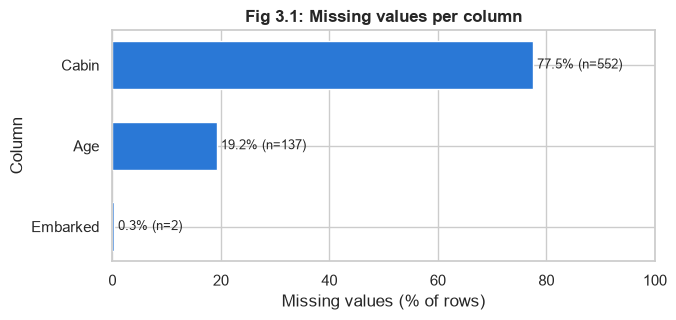

In [7]:
missing_percent = 100 * train_df.isna().mean()
missing_percent = missing_percent[missing_percent > 0].sort_values()
missing_counts = train_df[missing_percent.index].isna().sum()

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(missing_percent.index, missing_percent.to_numpy(), color=COLOR_MAIN, height=0.6)
ax.bar_label(bars, labels=[f"{p:.1f}% (n={missing_counts[c]})" for c, p in missing_percent.items()], padding=3, fontsize=9)
ax.set(title="Fig 3.1: Missing values per column", xlabel="Missing values (% of rows)", ylabel="Column", xlim=(0, 100))
plt.show()

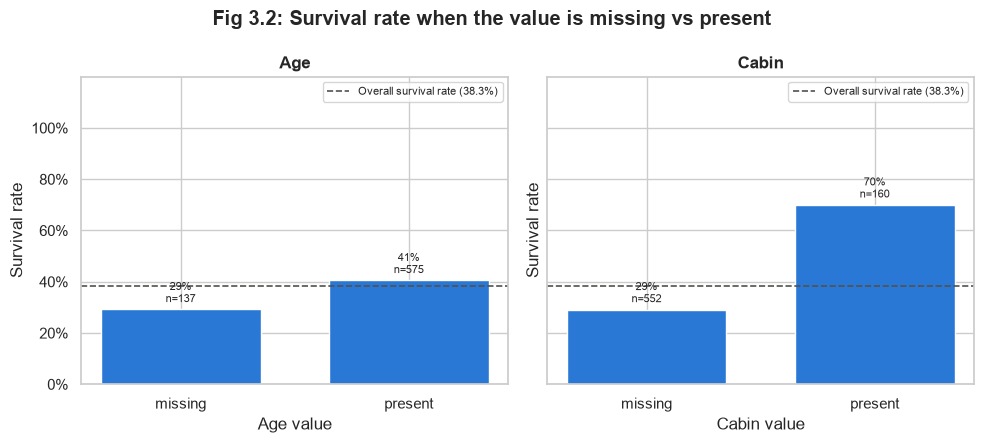

In [8]:
overall_rate = train_df[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, column in zip(axes, ["Age", "Cabin"]):
    # Display-only label: whether the value is missing in this row.
    is_missing = train_df[column].isna().map({True: "missing", False: "present"})
    plot_survival_rate(ax, is_missing, train_df[TARGET], overall_rate, order=["missing", "present"])
    ax.set(title=column, xlabel=f"{column} value", ylabel="Survival rate")
fig.suptitle("Fig 3.2: Survival rate when the value is missing vs present", fontweight="bold")
fig.tight_layout()
plt.show()

**Decision:**

- `Embarked`: fill with the training-set mode.
- `Age`: fill with the training-set median, and add a binary `Age_missing` indicator.
- `Cabin`: replace with a binary `Cabin_missing` indicator.
- Every input column gets a default fill value learned from the training set, for missing values at inference time.

## 4. Categorical variables (`Sex`, `Embarked`)

**Question:** How does survival differ across categories?

**What is shown:** Fig 4.1 shows the survival rate per category of `Sex` and `Embarked`, one subplot each; the number above each bar is the number of passengers, and the dashed line is the overall survival rate. Rows with missing `Embarked` are excluded.

Rows with missing Embarked excluded: 2


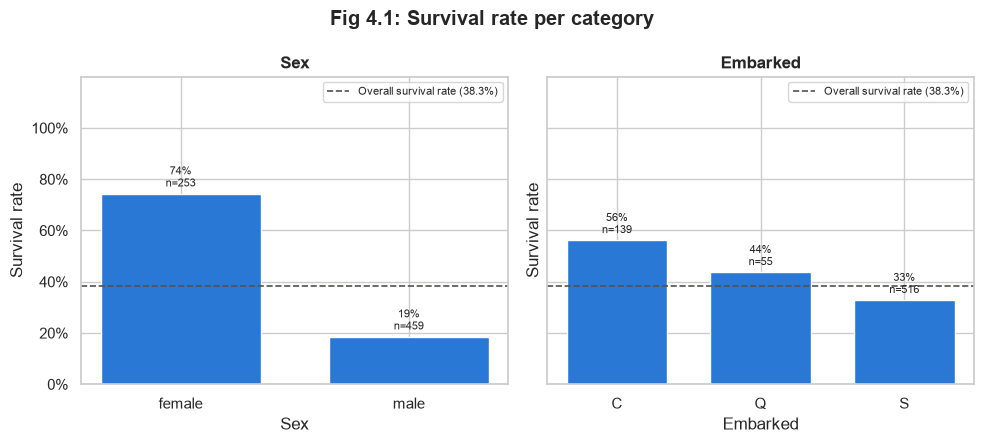

In [9]:
overall_rate = train_df[TARGET].mean()
print(f"Rows with missing Embarked excluded: {train_df['Embarked'].isna().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, column in zip(axes, ["Sex", "Embarked"]):
    rows = train_df.dropna(subset=[column])
    plot_survival_rate(ax, rows[column], rows[TARGET], overall_rate)
    ax.set(title=column, xlabel=column, ylabel="Survival rate")
fig.suptitle("Fig 4.1: Survival rate per category", fontweight="bold")
fig.tight_layout()
plt.show()

**Decision:**

- One-hot encode `Sex` and `Embarked`.

## 5. Discrete numeric variables (`Pclass`, `SibSp`, `Parch`)

**Question:** How does survival change across the values of each variable?

**What is shown:** Fig 5.1 shows the survival rate per value of `Pclass`, `SibSp` and `Parch`, one subplot each, values in ascending order; the number above each bar is the number of passengers, and the dashed line is the overall survival rate.

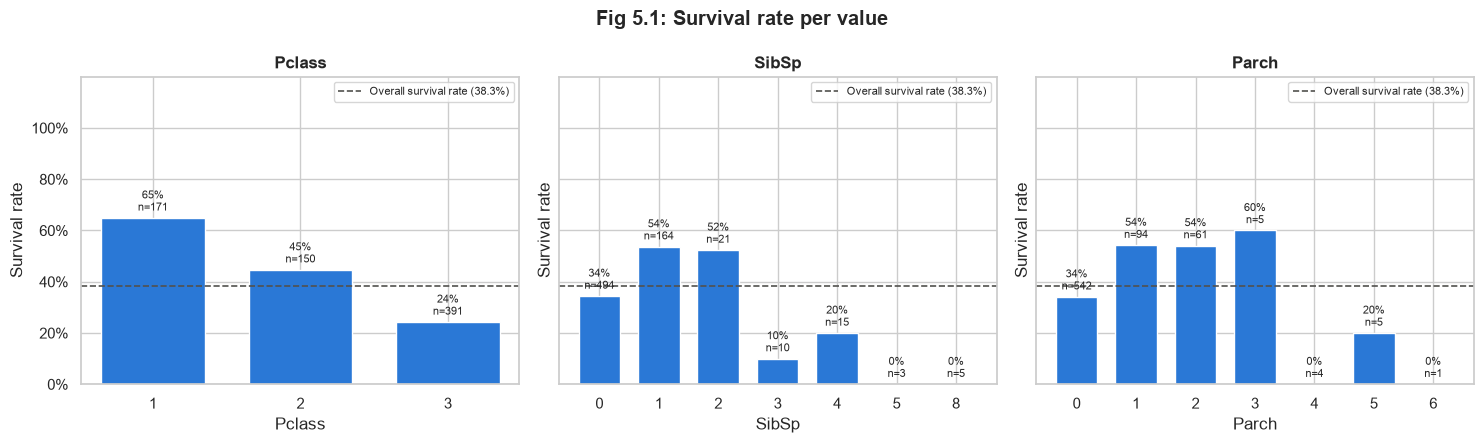

In [10]:
overall_rate = train_df[TARGET].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, column in zip(axes, ["Pclass", "SibSp", "Parch"]):
    plot_survival_rate(ax, train_df[column], train_df[TARGET], overall_rate)  # groupby sorts values ascending
    ax.set(title=column, xlabel=column, ylabel="Survival rate")
fig.suptitle("Fig 5.1: Survival rate per value", fontweight="bold")
fig.tight_layout()
plt.show()

**Decision:**

- Keep `Pclass`, `SibSp` and `Parch` as numeric features.

## 6. Continuous variables (`Age`, `Fare`)

**Question:** What do the distributions of `Age` and `Fare` look like?

**What is shown:** Fig 6.1 (`Age`) and Fig 6.2 (`Fare`) each show a histogram (number of passengers per value range) and a boxplot (the box spans the 25th to 75th percentile, the line inside is the median, dots are points beyond 1.5 x IQR). The lines below give the skewness of each variable (0 = symmetric, positive = long tail on the right) and the number of rows with `Fare` = 0. Missing values are excluded.

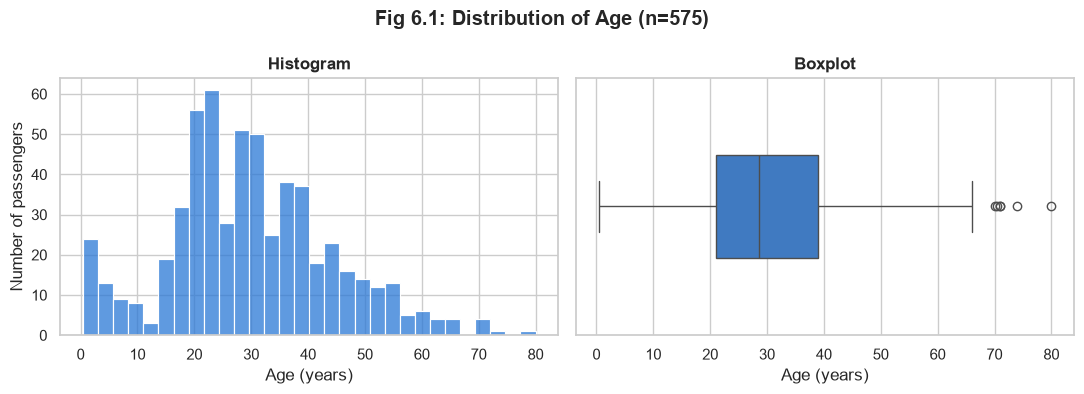

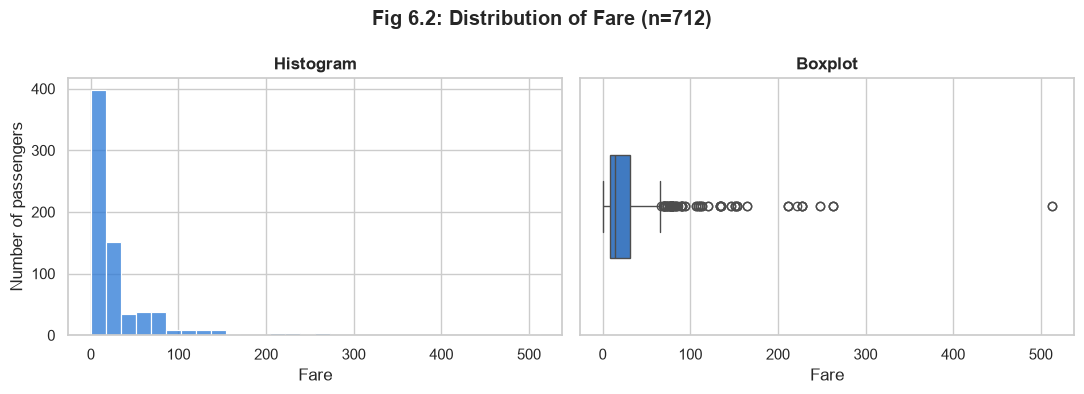

Skewness of Age: 0.35
Skewness of Fare: 4.65
Rows with Fare = 0: 14


In [11]:
AXIS_LABELS = {"Age": "Age (years)", "Fare": "Fare"}

for fig_number, column in enumerate(["Age", "Fare"], start=1):
    values = train_df[column].dropna()
    fig, (hist_ax, box_ax) = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(values, bins=30, color=COLOR_MAIN, ax=hist_ax)
    hist_ax.set(title="Histogram", xlabel=AXIS_LABELS[column], ylabel="Number of passengers")
    sns.boxplot(x=values, color=COLOR_MAIN, width=0.4, ax=box_ax)
    box_ax.set(title="Boxplot", xlabel=AXIS_LABELS[column])
    fig.suptitle(f"Fig 6.{fig_number}: Distribution of {column} (n={len(values)})", fontweight="bold")
    fig.tight_layout()
    plt.show()

for column in ["Age", "Fare"]:
    print(f"Skewness of {column}: {train_df[column].skew():.2f}")
print(f"Rows with Fare = 0: {(train_df['Fare'] == 0).sum()}")

**Decision:**

- Keep `Age` and `Fare` as continuous features.
- `Fare = 0` values are kept as valid values.
- Transformation and scaling are defined in preprocessing.

## 7. Text columns (`Name`, `Ticket`, `Cabin`)

**Question:** Can the text columns be used as features as they are?

**What is shown:** Table 7.1 gives the number of unique values of `Name`, `Ticket` and `Cabin`, and that number as a % of non-missing rows. Table 7.2 shows, for `Ticket`, how many tickets are shared by 1, 2, 3, … passengers. Table 7.3 lists the 10 most common `Ticket` shapes: each letter becomes `A`, each digit `9`, and a run of the same symbol becomes one symbol followed by `+` (for example `PC 17599` becomes `A+ 9+`).

In [12]:
TEXT_COLUMNS = ["Name", "Ticket", "Cabin"]

uniqueness = pd.DataFrame(
    {
        "unique values": [train_df[column].nunique() for column in TEXT_COLUMNS],
        "unique % of non-missing rows": [
            round(100 * train_df[column].nunique() / train_df[column].notna().sum(), 1) for column in TEXT_COLUMNS
        ],
    },
    index=pd.Index(TEXT_COLUMNS, name="column"),
)
show_table(uniqueness, "7.1", "Unique values of the text columns")

Table 7.1: Unique values of the text columns


,unique values,unique % of non-missing rows
column,,
Name,712,100.0
Ticket,571,80.2
Cabin,127,79.4


In [13]:
# Number of passengers on each ticket, then the number of tickets per group size.
passengers_per_ticket = train_df["Ticket"].value_counts()
ticket_sharing = passengers_per_ticket.value_counts().sort_index().to_frame("number of tickets")
ticket_sharing.index.name = "passengers sharing one ticket"
show_table(ticket_sharing, "7.2", "Ticket value sharing")

Table 7.2: Ticket value sharing


,number of tickets
passengers sharing one ticket,
1,476
2,69
3,14
4,6
5,4
6,2


In [14]:
def shape_pattern(value: str) -> str:
    """Letters -> A, digits -> 9, other characters kept; runs of the same symbol collapsed to 'symbol+'."""
    symbols = "".join("A" if ch.isalpha() else "9" if ch.isdigit() else ch for ch in value)
    return re.sub(r"(.)\1+", r"\1+", symbols)


ticket_patterns = train_df["Ticket"].dropna().map(shape_pattern).value_counts().head(10).to_frame("tickets")
ticket_patterns.index.name = "shape pattern"
show_table(ticket_patterns, "7.3", "10 most common Ticket shape patterns")

Table 7.3: 10 most common Ticket shape patterns


,tickets
shape pattern,
9+,522
A+ 9+,62
A.A. 9+,23
A+/A+ 9+,15
A/9 9+,12
A+/A 9. 9+,10
A/9. 9+,9
A.A.A. 9+,9
A./A. 9+,9


**Decision:**

- Drop `Name` and `Ticket`.
- `Cabin` is used only through `Cabin_missing` (section 3).

## 8. Correlation between the remaining features

**Question:** Are any of the remaining features near-duplicates of each other?

**What is shown:** Fig 8.1 shows the Spearman correlation between each pair of `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`, `Age_missing` and `Cabin_missing`; values go from -1 to +1, and values near -1 or +1 mean two features move together. Each cell uses the rows where both values are present; a blank cell means the correlation cannot be computed, because one of the two features has a single value on those rows.

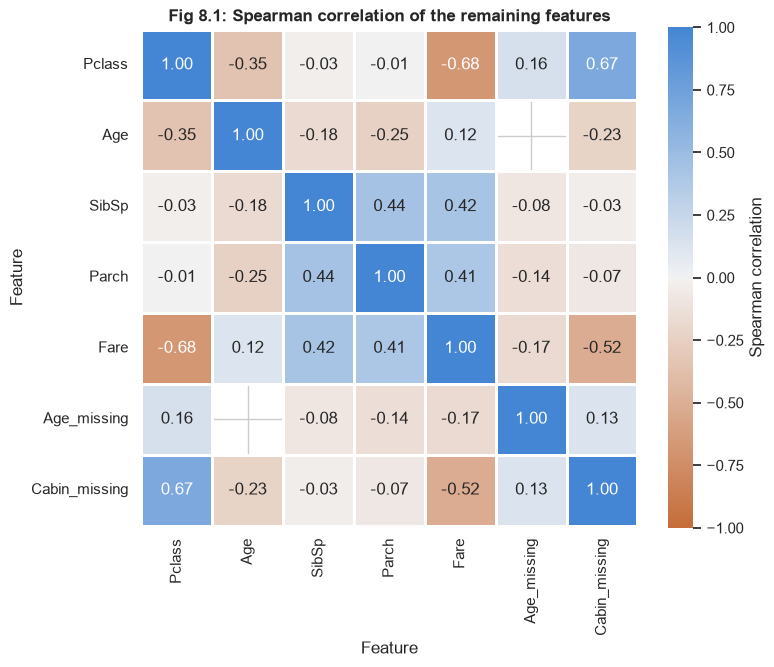

In [15]:
# Indicators built in a copy, for this plot only.
features = train_df[["Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
features["Age_missing"] = train_df["Age"].isna().astype(int)
features["Cabin_missing"] = train_df["Cabin"].isna().astype(int)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    features.corr(method="spearman"), annot=True, fmt=".2f", cmap=CORR_CMAP, vmin=-1, vmax=1, center=0,
    square=True, linewidths=1, linecolor="white", cbar_kws={"label": "Spearman correlation"}, ax=ax,
)
ax.set(title="Fig 8.1: Spearman correlation of the remaining features", xlabel="Feature", ylabel="Feature")
plt.show()

**Decision:**

- No pair is a near-duplicate; all remaining features are kept.

## 9. Summary

| Column | Decision |
| --- | --- |
| `PassengerId` | Dropped |
| `Name` | Dropped |
| `Ticket` | Dropped |
| `Cabin` | Replaced by `Cabin_missing` (0/1) |
| `Sex` | One-hot encoded |
| `Embarked` | Missing filled with training-set mode; one-hot encoded |
| `Pclass` | Numeric |
| `SibSp` | Numeric |
| `Parch` | Numeric |
| `Age` | Missing filled with training-set median; `Age_missing` (0/1) added |
| `Fare` | Continuous; transformation and scaling defined in preprocessing |
| All inputs | Default fill values learned from the training set, for missing values at inference |
